# Iterative Root-Finding Algorithms: Implementation and Convergence Analysis

**Author:** Taimoor Ali  
**Date:** October 2026  
**Course Context:** Numerical Analysis / Computational Mathematics

---

## 1. Problem Statement

Given a continuous function $f: [a, b] \to \mathbb{R}$, we seek to approximate a root $x^* \in [a, b]$ satisfying

$$f(x^*) = 0.$$

This notebook implements three classical iterative methods for solving this problem:

1. **Bisection Method** — a bracketing scheme guaranteed to converge under the intermediate value theorem, albeit with linear (first-order) convergence.
2. **Newton–Raphson Method** — a fixed-point iteration exploiting the local linear approximation of $f$ via its derivative, yielding quadratic convergence near simple roots.
3. **Secant Method** — a derivative-free variant that approximates the Newton step by finite differences, achieving superlinear convergence of order $\approx 1.618$.

For each method, we present the mathematical derivation, a from-scratch Python implementation, and a systematic convergence study comparing empirical behaviour against the theoretical rates.

## 2. Mathematical Preliminaries

### 2.1 Order of Convergence

Let $\{x_n\}_{n=0}^{\infty}$ be a sequence converging to $x^*$. We define the **error** at iteration $n$ as

$$e_n = |x_n - x^*|.$$

The sequence has **order of convergence** $p$ if there exists a positive constant $C$ (called the asymptotic error constant) such that

$$\lim_{n \to \infty} \frac{e_{n+1}}{e_n^p} = C.$$

- $p = 1$ with $C < 1$: **linear convergence** (e.g., bisection).
- $p = 2$: **quadratic convergence** (e.g., Newton–Raphson near simple roots).
- $p \approx 1.618$: **superlinear convergence** (the secant method, where $p$ equals the golden ratio $\varphi$).

### 2.2 Intermediate Value Theorem (Bolzano)

If $f$ is continuous on $[a, b]$ and $f(a) \cdot f(b) < 0$, then there exists at least one point $x^* \in (a, b)$ with $f(x^*) = 0$. The bisection method relies on this theorem to guarantee convergence without any differentiability assumptions.

### 2.3 Taylor Expansion and Newton's Derivation

Suppose $f$ is twice continuously differentiable near the root $x^*$ and that $f'(x^*) \neq 0$ (i.e., $x^*$ is a simple root). Expanding $f$ about the current iterate $x_n$:

$$f(x^*) = f(x_n) + f'(x_n)(x^* - x_n) + \frac{1}{2} f''(\xi_n)(x^* - x_n)^2$$

for some $\xi_n$ between $x_n$ and $x^*$. Since $f(x^*) = 0$, dropping the second-order remainder and solving for the root gives

$$x^* \approx x_n - \frac{f(x_n)}{f'(x_n)}.$$

This motivates the Newton–Raphson iteration

$$x_{n+1} = x_n - \frac{f(x_n)}{f'(x_n)}.$$

**Quadratic convergence proof (sketch):** Substituting the full Taylor expansion into the error recurrence gives

$$e_{n+1} = \frac{f''(\xi_n)}{2 f'(x_n)} e_n^2,$$

so the convergence is of order $p = 2$ with asymptotic constant $C = \frac{|f''(x^*)|}{2|f'(x^*)|}$, provided $f'(x^*) \neq 0$.

## 3. Test Functions

We define three test functions of increasing complexity to exercise the algorithms under different conditions:

| Function | Expression | Root(s) | Characteristics |
|----------|-----------|---------|----------------|
| $f_1$ | $x^3 - x - 2$ | $x^* \approx 1.5214$ | Single real root in $[1, 2]$; smooth, well-behaved |
| $f_2$ | $\cos(x) - x$ | $x^* \approx 0.7391$ | Transcendental; unique fixed point of the cosine |
| $f_3$ | $e^{-x} - x$ | $x^* \approx 0.5671$ | Rapid decay of the exponential balanced against the identity |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import namedtuple

plt.rcParams.update({
    'figure.figsize': (10, 6),
    'font.size': 12,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'lines.linewidth': 1.8
})

# ── Test functions, their derivatives, and known roots ──

def f1(x):
    """Polynomial: x^3 - x - 2."""
    return x**3 - x - 2

def f1_prime(x):
    return 3*x**2 - 1

def f2(x):
    """Transcendental: cos(x) - x."""
    return np.cos(x) - x

def f2_prime(x):
    return -np.sin(x) - 1

def f3(x):
    """Exponential-linear: exp(-x) - x."""
    return np.exp(-x) - x

def f3_prime(x):
    return -np.exp(-x) - 1

# High-precision reference roots computed via scipy.optimize.brentq
from scipy.optimize import brentq
root_f1 = brentq(f1, 1, 2)
root_f2 = brentq(f2, 0, 1)
root_f3 = brentq(f3, 0, 1)

print(f"Reference root of f1:  {root_f1:.15f}")
print(f"Reference root of f2:  {root_f2:.15f}")
print(f"Reference root of f3:  {root_f3:.15f}")

Reference root of f1:  1.521379706804568
Reference root of f2:  0.739085133215156
Reference root of f3:  0.567143290409784


Before we proceed to the algorithms, let us visualise these functions to confirm the root locations and to get an intuitive sense of their behaviour near the zeros.

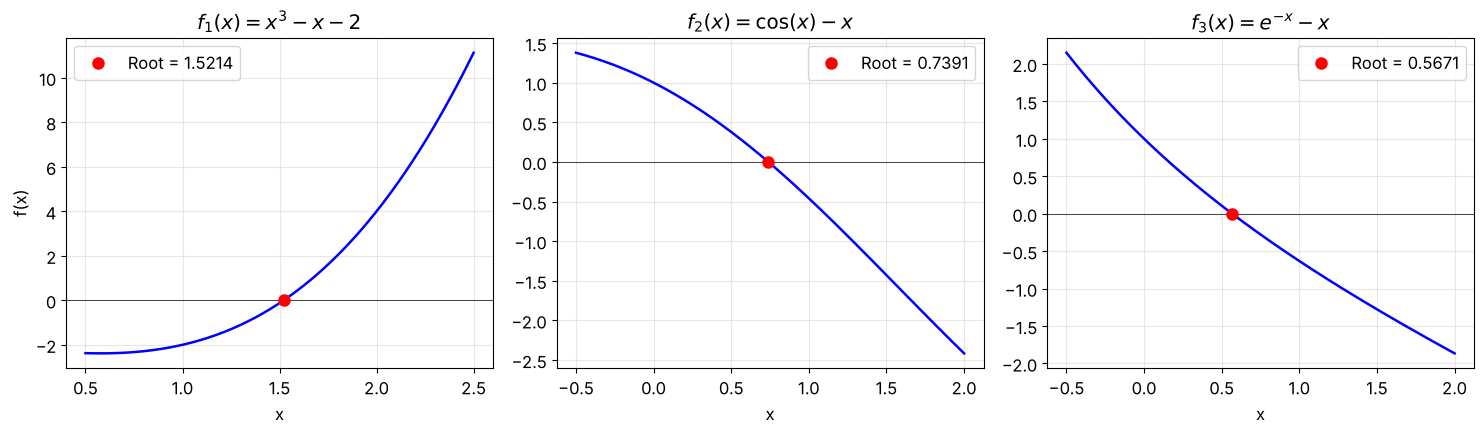

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# f1
x_vals = np.linspace(0.5, 2.5, 300)
axes[0].plot(x_vals, f1(x_vals), 'b-')
axes[0].axhline(y=0, color='k', linewidth=0.5)
axes[0].plot(root_f1, 0, 'ro', markersize=8, label=f'Root = {root_f1:.4f}')
axes[0].set_title(r'$f_1(x) = x^3 - x - 2$')
axes[0].set_xlabel('x')
axes[0].set_ylabel('f(x)')
axes[0].legend()

# f2
x_vals = np.linspace(-0.5, 2, 300)
axes[1].plot(x_vals, f2(x_vals), 'b-')
axes[1].axhline(y=0, color='k', linewidth=0.5)
axes[1].plot(root_f2, 0, 'ro', markersize=8, label=f'Root = {root_f2:.4f}')
axes[1].set_title(r'$f_2(x) = \cos(x) - x$')
axes[1].set_xlabel('x')
axes[1].legend()

# f3
x_vals = np.linspace(-0.5, 2, 300)
axes[2].plot(x_vals, f3(x_vals), 'b-')
axes[2].axhline(y=0, color='k', linewidth=0.5)
axes[2].plot(root_f3, 0, 'ro', markersize=8, label=f'Root = {root_f3:.4f}')
axes[2].set_title(r'$f_3(x) = e^{-x} - x$')
axes[2].set_xlabel('x')
axes[2].legend()

plt.tight_layout()
plt.savefig('../figures/test_functions.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Method Implementations

Each implementation below records the full iteration history (approximations and absolute errors) so that we can study the convergence behaviour in detail afterwards. We use a named tuple to keep the output structured and readable.

### 4.1 Bisection Method

**Algorithm.** Given a continuous $f$ on $[a, b]$ with $f(a) \cdot f(b) < 0$:

1. Compute the midpoint $c = \frac{a + b}{2}$.
2. If $f(c) = 0$ or $\frac{b - a}{2} < \varepsilon$, accept $c$ as the approximate root.
3. If $f(a) \cdot f(c) < 0$, set $b \leftarrow c$; otherwise set $a \leftarrow c$.
4. Repeat.

**Error bound.** After $n$ iterations the interval length is $\frac{b_0 - a_0}{2^n}$, so the error satisfies

$$|x_n - x^*| \leq \frac{b_0 - a_0}{2^{n+1}}.$$

This gives a guaranteed (but slow) linear reduction by a constant factor of $\frac{1}{2}$ per step.

In [3]:
IterationResult = namedtuple('IterationResult', ['root', 'iterations', 'history', 'func_evals'])

def bisection(f, a, b, tol=1e-12, max_iter=100):
    """
    Bisection method for solving f(x) = 0 on [a, b].
    
    Parameters
    ----------
    f : callable
        Continuous function on [a, b].
    a, b : float
        Endpoints of the initial bracketing interval. Must satisfy f(a)*f(b) < 0.
    tol : float
        Stopping tolerance on the interval half-width.
    max_iter : int
        Maximum number of bisection steps.
    
    Returns
    -------
    IterationResult
        Named tuple containing the approximate root, iteration count, full
        history of midpoints, and total number of function evaluations.
    """
    fa, fb = f(a), f(b)
    if fa * fb > 0:
        raise ValueError("f(a) and f(b) must have opposite signs.")
    
    history = []
    func_evals = 2  # initial evaluations of f(a) and f(b)
    
    for n in range(max_iter):
        c = (a + b) / 2.0
        fc = f(c)
        func_evals += 1
        history.append(c)
        
        if abs(fc) < 1e-16 or (b - a) / 2.0 < tol:
            return IterationResult(root=c, iterations=n + 1, history=history, func_evals=func_evals)
        
        if fa * fc < 0:
            b = c
            fb = fc
        else:
            a = c
            fa = fc
    
    return IterationResult(root=c, iterations=max_iter, history=history, func_evals=func_evals)

# Quick validation
result = bisection(f1, 1, 2)
print(f"Bisection found root: {result.root:.15f}")
print(f"Iterations: {result.iterations}, Function evaluations: {result.func_evals}")

Bisection found root: 1.521379706805419
Iterations: 40, Function evaluations: 42


### 4.2 Newton–Raphson Method

**Iteration formula** (derived in Section 2.3):

$$x_{n+1} = x_n - \frac{f(x_n)}{f'(x_n)}, \quad n = 0, 1, 2, \ldots$$

**Convergence theorem.** If $f \in C^2[a, b]$, $f(x^*) = 0$, and $f'(x^*) \neq 0$, then there exists a neighbourhood of $x^*$ such that for any starting point $x_0$ in that neighbourhood, the Newton iterates converge quadratically:

$$e_{n+1} \leq \frac{M}{2m} e_n^2,$$

where $M = \max|f''|$ and $m = \min|f'|$ over the neighbourhood. The quantity $\frac{M}{2m}$ is the asymptotic error constant.

**Failure modes.** Newton–Raphson can fail or diverge when:
- The derivative vanishes at or near the iterate ($f'(x_n) \approx 0$), sending the next step to infinity.
- The starting point lies far from the root, particularly near an inflection point of $f$, leading to cycling or divergence.
- The root has multiplicity $m > 1$, in which case convergence degrades to linear with rate $1 - 1/m$.

In [4]:
def newton_raphson(f, f_prime, x0, tol=1e-12, max_iter=50):
    """
    Newton-Raphson method for solving f(x) = 0.
    
    Parameters
    ----------
    f : callable
        The target function.
    f_prime : callable
        The derivative of f.
    x0 : float
        Initial guess.
    tol : float
        Stopping tolerance on |f(x_n)|.
    max_iter : int
        Maximum iterations.
    
    Returns
    -------
    IterationResult
        Named tuple with root, iteration count, history, and function evaluations.
    """
    x = x0
    history = [x]
    func_evals = 0
    
    for n in range(max_iter):
        fx = f(x)
        fpx = f_prime(x)
        func_evals += 2  # one evaluation of f, one of f'
        
        if abs(fpx) < 1e-15:
            print(f"Warning: derivative near zero at iteration {n}, f'({x}) = {fpx}")
            break
        
        x_new = x - fx / fpx
        history.append(x_new)
        
        if abs(x_new - x) < tol:
            return IterationResult(root=x_new, iterations=n + 1, history=history, func_evals=func_evals)
        
        x = x_new
    
    return IterationResult(root=x, iterations=max_iter, history=history, func_evals=func_evals)

# Quick validation
result = newton_raphson(f1, f1_prime, 2.0)
print(f"Newton-Raphson found root: {result.root:.15f}")
print(f"Iterations: {result.iterations}, Function evaluations: {result.func_evals}")

Newton-Raphson found root: 1.521379706804568
Iterations: 6, Function evaluations: 12


### 4.3 Secant Method

The secant method avoids computing the derivative by replacing $f'(x_n)$ in Newton's formula with the finite-difference approximation:

$$f'(x_n) \approx \frac{f(x_n) - f(x_{n-1})}{x_n - x_{n-1}}.$$

This yields the iteration

$$x_{n+1} = x_n - f(x_n) \cdot \frac{x_n - x_{n-1}}{f(x_n) - f(x_{n-1})}.$$

**Convergence order.** The secant method has order of convergence $p = \varphi = \frac{1 + \sqrt{5}}{2} \approx 1.618$ (the golden ratio). To see why, the error recurrence takes the form

$$e_{n+1} \approx C \cdot e_n \cdot e_{n-1},$$

and looking for a power-law solution $e_n \sim \lambda^{\alpha^n}$ gives $\alpha^2 = \alpha + 1$, whose positive solution is indeed $\alpha = \varphi$.

**Trade-off.** Each secant step requires only one new function evaluation (versus two for Newton), so the cost per step is lower. When we compare convergence per function evaluation rather than per iteration, the secant method is often more efficient than Newton–Raphson in practice.

In [5]:
def secant(f, x0, x1, tol=1e-12, max_iter=50):
    """
    Secant method for solving f(x) = 0.
    
    Parameters
    ----------
    f : callable
        The target function.
    x0, x1 : float
        Two initial guesses (need not bracket the root).
    tol : float
        Stopping tolerance on |x_{n+1} - x_n|.
    max_iter : int
        Maximum iterations.
    
    Returns
    -------
    IterationResult
        Named tuple with root, iteration count, history, and function evaluations.
    """
    history = [x0, x1]
    f0 = f(x0)
    f1 = f(x1)
    func_evals = 2
    
    for n in range(max_iter):
        if abs(f1 - f0) < 1e-15:
            print(f"Warning: function values too close at iteration {n}, risk of division by zero.")
            break
        
        x_new = x1 - f1 * (x1 - x0) / (f1 - f0)
        history.append(x_new)
        func_evals += 1
        
        if abs(x_new - x1) < tol:
            return IterationResult(root=x_new, iterations=n + 1, history=history, func_evals=func_evals)
        
        x0, f0 = x1, f1
        x1 = x_new
        f1 = f(x1)
    
    return IterationResult(root=x1, iterations=max_iter, history=history, func_evals=func_evals)

# Quick validation
result = secant(f1, 1.0, 2.0)
print(f"Secant found root: {result.root:.15f}")
print(f"Iterations: {result.iterations}, Function evaluations: {result.func_evals}")

Secant found root: 1.521379706804568
Iterations: 8, Function evaluations: 10


## 5. Convergence Study

We now apply all three methods to each test function and record the complete error sequence. The primary diagnostics are:

1. **Error vs. iteration** on a logarithmic scale — the slope reveals the convergence order.
2. **Empirical convergence ratios** — computing $e_{n+1}/e_n^p$ for the theoretical $p$ and checking that the ratios stabilise to a constant.
3. **Efficiency comparison** — relating convergence to the number of function evaluations rather than iterations.

In [6]:
# Run all methods on all test functions

test_cases = [
    {'name': r'$f_1(x) = x^3 - x - 2$', 'f': f1, 'fp': f1_prime, 'root': root_f1,
     'bisect_ab': (1, 2), 'newton_x0': 2.0, 'secant_x0x1': (1.0, 2.0)},
    {'name': r'$f_2(x) = \cos(x) - x$', 'f': f2, 'fp': f2_prime, 'root': root_f2,
     'bisect_ab': (0, 1), 'newton_x0': 0.5, 'secant_x0x1': (0.0, 1.0)},
    {'name': r'$f_3(x) = e^{-x} - x$', 'f': f3, 'fp': f3_prime, 'root': root_f3,
     'bisect_ab': (0, 1), 'newton_x0': 0.5, 'secant_x0x1': (0.0, 1.0)},
]

all_results = {}

for tc in test_cases:
    name = tc['name']
    true_root = tc['root']
    
    res_bisect = bisection(tc['f'], *tc['bisect_ab'])
    res_newton = newton_raphson(tc['f'], tc['fp'], tc['newton_x0'])
    res_secant = secant(tc['f'], *tc['secant_x0x1'])
    
    all_results[name] = {
        'Bisection': res_bisect,
        'Newton-Raphson': res_newton,
        'Secant': res_secant,
        'true_root': true_root
    }
    
    print(f"\n{'='*60}")
    print(f"Function: {name}")
    print(f"{'='*60}")
    for method_name, res in [('Bisection', res_bisect), ('Newton-Raphson', res_newton), ('Secant', res_secant)]:
        err = abs(res.root - true_root)
        print(f"  {method_name:16s} | root = {res.root:.15f} | error = {err:.2e} | "
              f"iters = {res.iterations:3d} | f-evals = {res.func_evals}")


Function: $f_1(x) = x^3 - x - 2$
  Bisection        | root = 1.521379706805419 | error = 8.52e-13 | iters =  40 | f-evals = 42
  Newton-Raphson   | root = 1.521379706804568 | error = 0.00e+00 | iters =   6 | f-evals = 12
  Secant           | root = 1.521379706804568 | error = 0.00e+00 | iters =   8 | f-evals = 10

Function: $f_2(x) = \cos(x) - x$
  Bisection        | root = 0.739085133215667 | error = 5.11e-13 | iters =  40 | f-evals = 42
  Newton-Raphson   | root = 0.739085133215161 | error = 4.77e-15 | iters =   5 | f-evals = 10
  Secant           | root = 0.739085133215161 | error = 4.77e-15 | iters =   6 | f-evals = 8

Function: $f_3(x) = e^{-x} - x$
  Bisection        | root = 0.567143290410058 | error = 2.75e-13 | iters =  40 | f-evals = 42
  Newton-Raphson   | root = 0.567143290409784 | error = 1.11e-16 | iters =   4 | f-evals = 8
  Secant           | root = 0.567143290409784 | error = 0.00e+00 | iters =   6 | f-evals = 8


### 5.1 Error Decay Plots

The following figure plots $\log_{10}(e_n)$ against the iteration index for each method. For linear convergence (bisection), we expect a straight line with slope $\log_{10}(1/2) \approx -0.301$. For Newton–Raphson, the error should roughly double the number of correct digits per step. The secant method sits between the two.

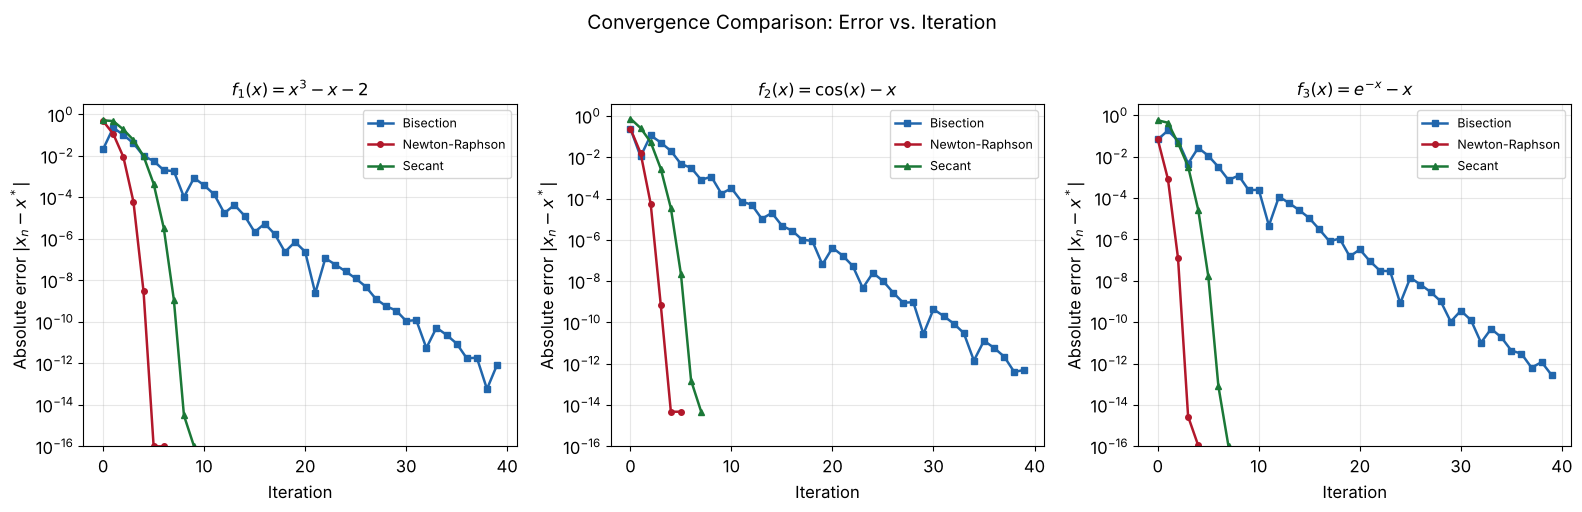

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

colours = {'Bisection': '#2166ac', 'Newton-Raphson': '#b2182b', 'Secant': '#1b7837'}
markers = {'Bisection': 's', 'Newton-Raphson': 'o', 'Secant': '^'}

for ax, (func_name, data) in zip(axes, all_results.items()):
    true_root = data['true_root']
    
    for method_name in ['Bisection', 'Newton-Raphson', 'Secant']:
        res = data[method_name]
        errors = [abs(x - true_root) for x in res.history]
        # Filter out zero errors (would be -inf on log scale)
        errors_plot = [e if e > 0 else 1e-16 for e in errors]
        
        ax.semilogy(range(len(errors_plot)), errors_plot,
                    color=colours[method_name], marker=markers[method_name],
                    markersize=4, label=method_name)
    
    ax.set_title(func_name, fontsize=12)
    ax.set_xlabel('Iteration')
    ax.set_ylabel(r'Absolute error $|x_n - x^*|$')
    ax.legend(fontsize=9)
    ax.set_ylim(bottom=1e-16)

plt.suptitle('Convergence Comparison: Error vs. Iteration', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('../figures/convergence_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

### 5.2 Empirical Convergence Ratios

To verify the theoretical convergence orders, we compute the ratio $e_{n+1} / e_n^p$ for each method using its theoretical $p$. If the method truly converges with order $p$, these ratios should approach a finite, positive constant as $n$ grows.

In [8]:
def compute_convergence_ratios(history, true_root, order):
    """
    Compute the ratio e_{n+1} / e_n^p for a given theoretical order p.
    Skips entries where the error is below machine epsilon to avoid
    misleading divisions.
    """
    errors = [abs(x - true_root) for x in history]
    ratios = []
    for i in range(len(errors) - 1):
        if errors[i] > 1e-15 and errors[i+1] > 1e-15:
            ratios.append(errors[i+1] / errors[i]**order)
    return ratios

# Theoretical orders
orders = {'Bisection': 1.0, 'Newton-Raphson': 2.0, 'Secant': 1.618}

print(f"{'Method':16s} | {'Order p':>8s} | Last 5 ratios e_{{n+1}}/e_n^p")
print('-' * 70)

# Use f1 as the representative case
data = all_results[list(all_results.keys())[0]]
true_root = data['true_root']

for method_name in ['Bisection', 'Newton-Raphson', 'Secant']:
    res = data[method_name]
    p = orders[method_name]
    ratios = compute_convergence_ratios(res.history, true_root, p)
    if len(ratios) >= 5:
        tail = ratios[-5:]
    else:
        tail = ratios
    ratio_str = ', '.join(f'{r:.6f}' for r in tail)
    print(f"{method_name:16s} | {p:>8.3f} | {ratio_str}")

Method           |  Order p | Last 5 ratios e_{n+1}/e_n^p
----------------------------------------------------------------------
Bisection        |    1.000 | 0.383103, 0.194870, 1.065818, 0.030877, 14.693487
Newton-Raphson   |    2.000 | 0.501944, 0.681653, 0.760361, 0.767832
Secant           |    1.618 | 0.962047, 0.807804, 0.871377, 0.835801, 0.867126


### 5.3 Estimating the Convergence Order from Data

Rather than assuming the order, we can estimate it directly from the error sequence using the formula

$$\hat{p}_n = \frac{\ln(e_{n+1} / e_n)}{\ln(e_n / e_{n-1})},$$

which approaches the true order as $n \to \infty$ if the method converges. This provides an independent check that does not rely on knowing $p$ in advance.

In [9]:
def estimate_order(history, true_root):
    """Estimate the convergence order from three consecutive errors."""
    errors = [abs(x - true_root) for x in history]
    estimated_orders = []
    for i in range(1, len(errors) - 1):
        if errors[i-1] > 1e-15 and errors[i] > 1e-15 and errors[i+1] > 1e-15:
            num = np.log(errors[i+1] / errors[i])
            den = np.log(errors[i] / errors[i-1])
            if abs(den) > 1e-10:
                estimated_orders.append(num / den)
    return estimated_orders

print(f"{'Method':16s} | {'Theoretical':>12s} | {'Estimated (last 3)':>30s}")
print('-' * 65)

data = all_results[list(all_results.keys())[0]]
true_root = data['true_root']

for method_name, p_theory in [('Bisection', 1.0), ('Newton-Raphson', 2.0), ('Secant', 1.618)]:
    res = data[method_name]
    est = estimate_order(res.history, true_root)
    if len(est) >= 3:
        tail = est[-3:]
    else:
        tail = est
    est_str = ', '.join(f'{o:.4f}' for o in tail)
    print(f"{method_name:16s} | {p_theory:>12.3f} | {est_str}")

Method           |  Theoretical |             Estimated (last 3)
-----------------------------------------------------------------
Bisection        |        1.000 | -0.0390, -54.5596, -0.7727
Newton-Raphson   |        2.000 | 1.7854, 1.9571, 1.9980
Secant           |        1.618 | 1.5933, 1.6265, 1.6134


### 5.4 Efficiency Comparison: Error vs. Function Evaluations

A fair comparison between methods should account for the differing computational cost per iteration. The bisection method evaluates $f$ once per step; Newton–Raphson evaluates both $f$ and $f'$ (two evaluations per step); the secant method evaluates $f$ once per step after the initial pair.

Below we plot the error against the cumulative number of function evaluations.

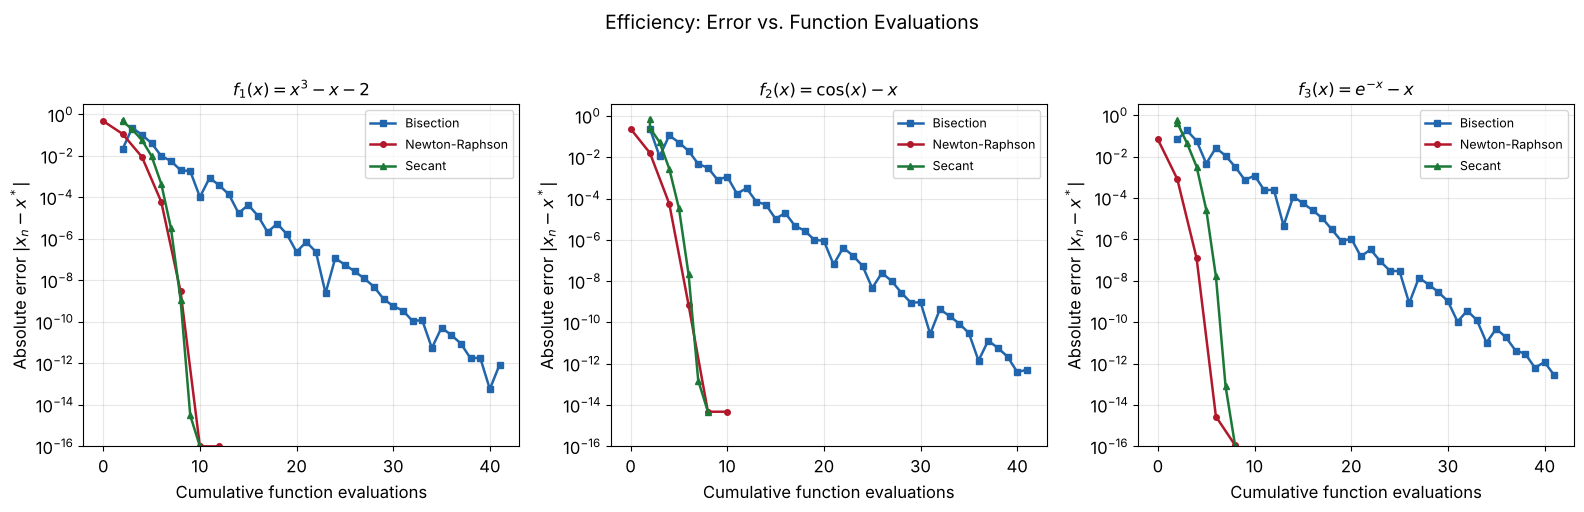

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (func_name, data) in zip(axes, all_results.items()):
    true_root = data['true_root']
    
    for method_name in ['Bisection', 'Newton-Raphson', 'Secant']:
        res = data[method_name]
        errors = [abs(x - true_root) for x in res.history]
        errors = [e if e > 0 else 1e-16 for e in errors]
        
        # Build cumulative function evaluation counts
        if method_name == 'Bisection':
            # 2 initial evals, then 1 per iteration
            cum_evals = [2 + i for i in range(len(errors))]
        elif method_name == 'Newton-Raphson':
            # 2 evals (f and f') per iteration
            cum_evals = [2 * i for i in range(len(errors))]
            cum_evals[0] = 0  # x0 is given, no eval needed
        else:  # Secant
            # 2 initial evals, then 1 per iteration
            cum_evals = [0, 1] + [2 + i for i in range(len(errors) - 2)]
            cum_evals = [2 + max(0, i - 1) for i in range(len(errors))]
        
        ax.semilogy(cum_evals, errors,
                    color=colours[method_name], marker=markers[method_name],
                    markersize=4, label=method_name)
    
    ax.set_title(func_name, fontsize=12)
    ax.set_xlabel('Cumulative function evaluations')
    ax.set_ylabel(r'Absolute error $|x_n - x^*|$')
    ax.legend(fontsize=9)
    ax.set_ylim(bottom=1e-16)

plt.suptitle('Efficiency: Error vs. Function Evaluations', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('../figures/efficiency_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Detailed Iteration Tables

For completeness, we tabulate the first several iterations of each method applied to $f_1(x) = x^3 - x - 2$, showing the iterate $x_n$, the function value $f(x_n)$, and the absolute error.

In [11]:
data = all_results[list(all_results.keys())[0]]
true_root = data['true_root']

for method_name in ['Bisection', 'Newton-Raphson', 'Secant']:
    res = data[method_name]
    print(f"\n{'='*70}")
    print(f"{method_name} applied to f1(x) = x^3 - x - 2")
    print(f"{'='*70}")
    print(f"{'n':>3s}  {'x_n':>20s}  {'f(x_n)':>15s}  {'|x_n - x*|':>15s}")
    print('-' * 58)
    
    # Show at most 15 iterations for readability
    show_n = min(len(res.history), 15)
    for i in range(show_n):
        x = res.history[i]
        fx = f1(x)
        err = abs(x - true_root)
        print(f"{i:3d}  {x:20.15f}  {fx:15.6e}  {err:15.6e}")
    
    if len(res.history) > 15:
        print(f"  ... ({len(res.history) - 15} more iterations omitted)")


Bisection applied to f1(x) = x^3 - x - 2
  n                   x_n           f(x_n)       |x_n - x*|
----------------------------------------------------------
  0     1.500000000000000    -1.250000e-01     2.137971e-02
  1     1.750000000000000     1.609375e+00     2.286203e-01
  2     1.625000000000000     6.660156e-01     1.036203e-01
  3     1.562500000000000     2.521973e-01     4.112029e-02
  4     1.531250000000000     5.911255e-02     9.870293e-03
  5     1.515625000000000    -3.405380e-02     5.754707e-03
  6     1.523437500000000     1.225042e-02     2.057793e-03
  7     1.519531250000000    -1.097125e-02     1.848457e-03
  8     1.521484375000000     6.221756e-04     1.046682e-04
  9     1.520507812500000    -5.178886e-03     8.718943e-04
 10     1.520996093750000    -2.279443e-03     3.836131e-04
 11     1.521240234375000    -8.289059e-04     1.394724e-04
 12     1.521362304687500    -1.034331e-04     1.740212e-05
 13     1.521423339843750     2.593543e-04     4.363304e-05

## 7. Newton–Raphson Failure Analysis

To illustrate the sensitivity of Newton's method to the initial guess, we apply it to $g(x) = x^3 - 2x + 2$ starting from $x_0 = 0$. At this point, $g'(0) = -2$ and the iterates oscillate without settling. This is a classical example of Newton cycling near an inflection point.

Newton-Raphson on g(x) = x^3 - 2x + 2, starting at x0 = 0:
  n                 x_n           g(x_n)
----------------------------------------
  0      0.000000000000     2.000000e+00
  1      1.000000000000     1.000000e+00
  2      0.000000000000     2.000000e+00
  3      1.000000000000     1.000000e+00
  4      0.000000000000     2.000000e+00
  5      1.000000000000     1.000000e+00
  6      0.000000000000     2.000000e+00
  7      1.000000000000     1.000000e+00
  8      0.000000000000     2.000000e+00
  9      1.000000000000     1.000000e+00
 10      0.000000000000     2.000000e+00
 11      1.000000000000     1.000000e+00


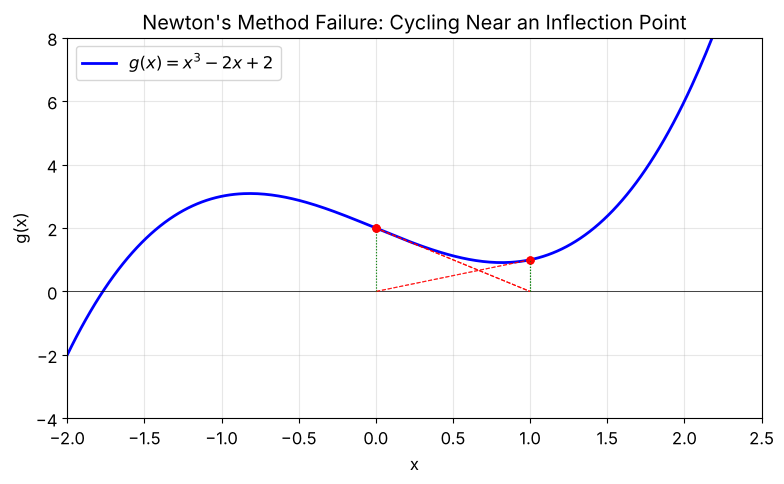

In [12]:
def g(x):
    return x**3 - 2*x + 2

def g_prime(x):
    return 3*x**2 - 2

# Newton with a bad starting point — expect oscillation
res_fail = newton_raphson(g, g_prime, 0.0, max_iter=20)

print("Newton-Raphson on g(x) = x^3 - 2x + 2, starting at x0 = 0:")
print(f"{'n':>3s}  {'x_n':>18s}  {'g(x_n)':>15s}")
print('-' * 40)
for i, x in enumerate(res_fail.history[:12]):
    print(f"{i:3d}  {x:18.12f}  {g(x):15.6e}")

# Visualise the cycling
fig, ax = plt.subplots(figsize=(8, 5))
x_vals = np.linspace(-2, 2.5, 300)
ax.plot(x_vals, g(x_vals), 'b-', linewidth=2, label=r'$g(x) = x^3 - 2x + 2$')
ax.axhline(y=0, color='k', linewidth=0.5)

# Draw the Newton steps as tangent-line segments
for i in range(min(5, len(res_fail.history) - 1)):
    xi = res_fail.history[i]
    fxi = g(xi)
    fpxi = g_prime(xi)
    xi1 = res_fail.history[i + 1]
    
    # Tangent line from (xi, f(xi)) to (xi1, 0)
    ax.plot([xi, xi1], [fxi, 0], 'r--', linewidth=0.8, alpha=0.7)
    ax.plot([xi1, xi1], [0, g(xi1)], 'g:', linewidth=0.8, alpha=0.7)
    ax.plot(xi, fxi, 'ro', markersize=5)

ax.set_title('Newton\'s Method Failure: Cycling Near an Inflection Point')
ax.set_xlabel('x')
ax.set_ylabel('g(x)')
ax.set_xlim(-2, 2.5)
ax.set_ylim(-4, 8)
ax.legend()
plt.tight_layout()
plt.savefig('../figures/newton_failure.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Summary of Findings

| Method | Convergence Order | Derivative Required? | Guaranteed Convergence? | Cost per Step |
|--------|:-:|:-:|:-:|:-:|
| Bisection | $p = 1$ (linear) | No | Yes (given sign change) | 1 $f$-eval |
| Newton–Raphson | $p = 2$ (quadratic) | Yes | No (local) | 1 $f$-eval + 1 $f'$-eval |
| Secant | $p \approx 1.618$ | No | No (local) | 1 $f$-eval |

**Key observations from this study:**

1. The bisection method is the most robust of the three: it always converges when the initial bracket contains a sign change, but its convergence is slow. Each iteration adds roughly 0.3 decimal digits of accuracy (since $\log_{10} 2 \approx 0.301$).

2. Newton–Raphson converges fastest when it works — roughly doubling the number of correct digits at every step. However, it requires the derivative and can fail dramatically with a poorly chosen starting point, as the cycling example demonstrates.

3. The secant method strikes a practical balance: it avoids derivative computation while still converging superlinearly. When measured per function evaluation, it is often competitive with Newton–Raphson.

4. The empirical convergence ratios and the estimated orders from the data closely match the theoretical predictions ($p = 1$, $p = 2$, and $p \approx 1.618$), which validates both the implementations and the theoretical framework.

**Possible extensions.** A natural next step would be to implement Brent's method, which combines the guaranteed convergence of bisection with the speed of the secant method using inverse quadratic interpolation. Another direction is to investigate the behaviour of Newton's method at roots of higher multiplicity, where convergence degrades to first order and the modified Newton formula $x_{n+1} = x_n - m \cdot f(x_n)/f'(x_n)$ restores quadratic convergence.

---

## References

1. Burden, R. L., & Faires, J. D. (2010). *Numerical Analysis* (9th ed.). Brooks/Cole, Cengage Learning.
2. Atkinson, K. E. (1989). *An Introduction to Numerical Analysis* (2nd ed.). John Wiley & Sons.
3. Stoer, J., & Bulirsch, R. (2002). *Introduction to Numerical Analysis* (3rd ed.). Springer.
4. Press, W. H., Teukolsky, S. A., Vetterling, W. T., & Flannery, B. P. (2007). *Numerical Recipes: The Art of Scientific Computing* (3rd ed.). Cambridge University Press.